
📦 Celda 1: Carga de librerías


Esta celda importa todas las bibliotecas necesarias para el análisis y la construcción del modelo de machine learning. Incluye `pandas` para manejo de datos, `numpy` para operaciones numéricas, `matplotlib` y `seaborn` para visualización, y módulos de `sklearn` y `tensorflow.keras` para el preprocesamiento de datos, división del dataset, escalado, construcción del modelo y evaluación.

In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report

from tensorflow import keras
from keras import layers
from keras.callbacks import EarlyStopping


📥 Celda 2: Cargar y explorar el dataset


Aquí se carga el archivo CSV `df_CC_NO_ED_Desbalanceado_Sin_Outlier.csv` en un DataFrame de pandas llamado `df`. Luego, se imprimen los nombres de las columnas para verificar que se han cargado correctamente y se muestra el conteo de valores únicos en la columna `fraud_category_5_classes` para entender la distribución de las clases (se observa un desbalance significativo).

In [101]:
df = pd.read_csv('/content/df_CC_SI_ED_Balanceado_Con_Outliers.csv')
# Verifica columnas clave
print(df.columns)
print(df['fraud_category_5_classes'].value_counts())


Index(['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT',
       'type_PAYMENT', 'type_TRANSFER', 'fraud_category_5_classes'],
      dtype='object')
fraud_category_5_classes
Fraude - Retiro (Cash Out) - Alto Monto    1200
Fraude - Transferencia - Alto Monto        1200
Legitima                                   1200
Fraude - Transferencia - Bajo Monto        1200
Fraude - Retiro (Cash Out) - Bajo Monto    1200
Name: count, dtype: int64


🧹 Celda 3: Selección de variables predictoras y objetivo

En esta celda, se seleccionan las columnas `'amount'` y `'oldbalanceOrg'` como características de entrada (`X`) y la columna `'fraud_category_5_classes'` como la variable objetivo (`y_labels`). La variable objetivo, que está en formato de texto, se codifica primero en valores numéricos usando `LabelEncoder` (`y_encoded`) y luego se transforma a un formato one-hot encoding (`y_categorical`), que es necesario para la capa de salida del modelo con activación `softmax`.

In [102]:
# Características de entrada (puedes añadir más si lo deseas)
X = df[['amount', 'oldbalanceOrg']].copy()

# Variable objetivo (ya está en texto)
y_labels = df['fraud_category_5_classes']

# Codificamos en números las etiquetas
le = LabelEncoder()
y_encoded = le.fit_transform(y_labels)

# Las convertimos a one-hot (necesario para softmax)
y_categorical = keras.utils.to_categorical(y_encoded, num_classes=5)


🧪 Celda 4: Separar datos de entrenamiento y prueba

Separar datos de entrenamiento y prueba Esta celda divide el dataset en conjuntos de entrenamiento y prueba utilizando train_test_split. Se reserva el 30% de los datos para prueba (test_size=0.3). El parámetro random_state=42 asegura la reproducibilidad de la división, y stratify=y_encoded mantiene la misma proporción de clases en los conjuntos de entrenamiento y prueba, lo cual es crucial dado el desbalance de clases.

In [103]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.3, random_state=42, stratify=y_encoded)


⚖️ Celda 5: Escalar características

 Aquí se utiliza StandardScaler para estandarizar las características de entrada (X_train y X_test). La estandarización transforma los datos para que tengan media 0 y desviación estándar 1, lo cual es importante para muchos algoritmos de machine learning, especialmente para redes neuronales. fit_transform se usa en el conjunto de entrenamiento para aprender los parámetros de escalado (media y desviación estándar) y transformar los datos, mientras que solo transform se usa en el conjunto de prueba para aplicar los mismos parámetros aprendidos.

In [104]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


🧱 Celda 6: Definición del modelo con regularización y dropout

Esta celda define la arquitectura de la red neuronal secuencial utilizando Keras. El modelo tiene dos capas densas ocultas con activación 'relu' y regularización L2 (`kernel_regularizer=keras.regularizers.l2(0.01)`) para ayudar a prevenir el sobreajuste. También se añade una capa de Dropout (`layers.Dropout(0.3)`) después de cada capa oculta, que desactiva aleatoriamente un 30% de las neuronas durante el entrenamiento para mejorar la generalización. La capa de salida tiene 5 neuronas (una por cada clase) y utiliza la activación 'softmax' para producir probabilidades para cada clase. Se incluye un `UserWarning` sobre `input_shape` en versiones recientes de Keras, sugiriendo usar `Input(shape)` como primera capa, pero el código sigue siendo funcional en este caso.

In [105]:
model = keras.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train.shape[1],),
                 kernel_regularizer=keras.regularizers.l2(0.01)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu',
                 kernel_regularizer=keras.regularizers.l2(0.01)),
    layers.Dropout(0.3),
    layers.Dense(5, activation='softmax')
])


/usr/local/lib/python3.11/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


⚙️ Celda 7: Compilar el modelo
En esta celda, se compila el modelo definido. Se especifica el optimizador 'adam', la función de pérdida 'categorical_crossentropy' (apropiada para clasificación multiclase con one-hot encoding), y la métrica 'accuracy' para evaluar el rendimiento durante el entrenamiento.

In [106]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


🛑 Celda 8: Entrenamiento con EarlyStopping

Esta celda entrena el modelo utilizando los datos escalados de entrenamiento (`X_train_scaled`, `y_train`). Se utiliza `EarlyStopping` como callback para detener el entrenamiento si la pérdida de validación (`val_loss`) no mejora durante 10 épocas (`patience=10`), y `restore_best_weights=True` asegura que se conserven los pesos del modelo con la mejor pérdida de validación. El entrenamiento se ejecuta por hasta 100 épocas (`epochs=100`) con un tamaño de lote de 32 (`batch_size=32`). Se utiliza un 20% del conjunto de entrenamiento como conjunto de validación (`validation_split=0.2`).

In [107]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history = model.fit(X_train_scaled, y_train,
                    validation_split=0.2,
                    epochs=100,
                    batch_size=32,
                    callbacks=[early_stop],
                    verbose=1)


Epoch 1/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.2626 - loss: 2.1119 - val_accuracy: 0.4845 - val_loss: 1.7409
Epoch 2/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3703 - loss: 1.6818 - val_accuracy: 0.4083 - val_loss: 1.5378
Epoch 3/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3821 - loss: 1.5284 - val_accuracy: 0.4440 - val_loss: 1.4416
Epoch 4/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4221 - loss: 1.4516 - val_accuracy: 0.4214 - val_loss: 1.3952
Epoch 5/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4401 - loss: 1.4196 - val_accuracy: 0.4917 - val_loss: 1.3753
Epoch 6/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4256 - loss: 1.3899 - val_accuracy: 0.4798 - val_loss: 1.3560
Epoch 7/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4502 - loss: 1.3830 - val_accuracy: 0.4821 - val_loss: 1.3380
Epoch 8/100
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4430 - loss: 1.3779 - val_acc

📈 Celda 9: Gráficas de entrenamiento
Esta celda genera dos gráficas utilizando `matplotlib`: una muestra la pérdida (loss) del entrenamiento y la validación a lo largo de las épocas, y la otra muestra la precisión (accuracy) del entrenamiento y la validación. Estas gráficas son útiles para visualizar el proceso de entrenamiento y detectar si el modelo está sobreajustando o subajustando.

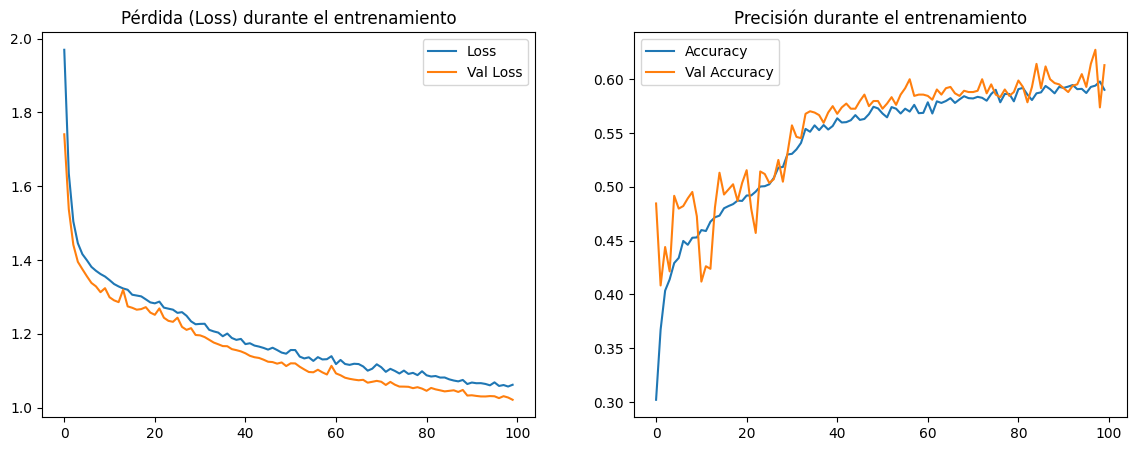

In [108]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Pérdida (Loss) durante el entrenamiento')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Precisión durante el entrenamiento')

plt.show()


🧪 Celda 10: Evaluación del modelo
Aquí se evalúa el rendimiento del modelo en el conjunto de prueba (`X_test_scaled`). Se hacen predicciones (`model.predict`), se convierten las predicciones one-hot a clases numéricas (`np.argmax`), y se obtienen los nombres de las clases correspondientes. Luego, se genera e imprime un reporte de clasificación detallado utilizando `classification_report` de sklearn, que incluye métricas como precisión, recall, f1-score y soporte para cada clase. Finalmente, se extraen y muestran las métricas generales (accuracy, precision, recall, f1-score) utilizando el promedio ponderado (`weighted avg`) del reporte.

In [109]:
# Predicciones
y_pred = model.predict(X_test_scaled)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Get the unique classes present in the true and predicted labels
unique_classes = np.unique(np.concatenate((y_true_classes, y_pred_classes)))

# Get the corresponding class names from le.classes_
target_class_names = le.classes_[unique_classes]

# Reporte de clasificación
# Modificado para generar el reporte como un diccionario
report_dict = classification_report(y_true_classes, y_pred_classes, target_names=target_class_names, output_dict=True)

# Imprimir el reporte formateado
print(classification_report(y_true_classes, y_pred_classes, target_names=target_class_names))

# Extraer y mostrar las métricas generales (weighted avg)
general_accuracy = report_dict['accuracy']
general_precision = report_dict['weighted avg']['precision']
general_recall = report_dict['weighted avg']['recall']
general_f1_score = report_dict['weighted avg']['f1-score']

print("\nMétricas Generales del Modelo (Weighted Average):")
print(f"Accuracy: {general_accuracy:.4f}")
print(f"Precision: {general_precision:.4f}")
print(f"Recall: {general_recall:.4f}")
print(f"F1-Score: {general_f1_score:.4f}")

57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
                                         precision    recall  f1-score   support

Fraude - Retiro (Cash Out) - Alto Monto       0.70      0.47      0.56       360
Fraude - Retiro (Cash Out) - Bajo Monto       0.42      0.94      0.58       360
    Fraude - Transferencia - Alto Monto       0.95      0.16      0.27       360
    Fraude - Transferencia - Bajo Monto       0.69      0.89      0.78       360
                               Legitima       1.00      0.63      0.77       360

                               accuracy                           0.62      1800
                              macro avg       0.75      0.62      0.59      1800
                           weighted avg       0.75      0.62      0.59      1800


Métricas Generales del Modelo (Weighted Average):
Accuracy: 0.6161
Precision: 0.7515
Recall: 0.6161
F1-Score: 0.5917


📊 Celda 11: Gráfica de barras de predicciones por clase

Esta celda crea una gráfica de barras utilizando `seaborn` que muestra el conteo de predicciones para cada una de las clases en el conjunto de prueba. Esto ayuda a visualizar cómo se distribuyen las predicciones del modelo entre las diferentes categorías.

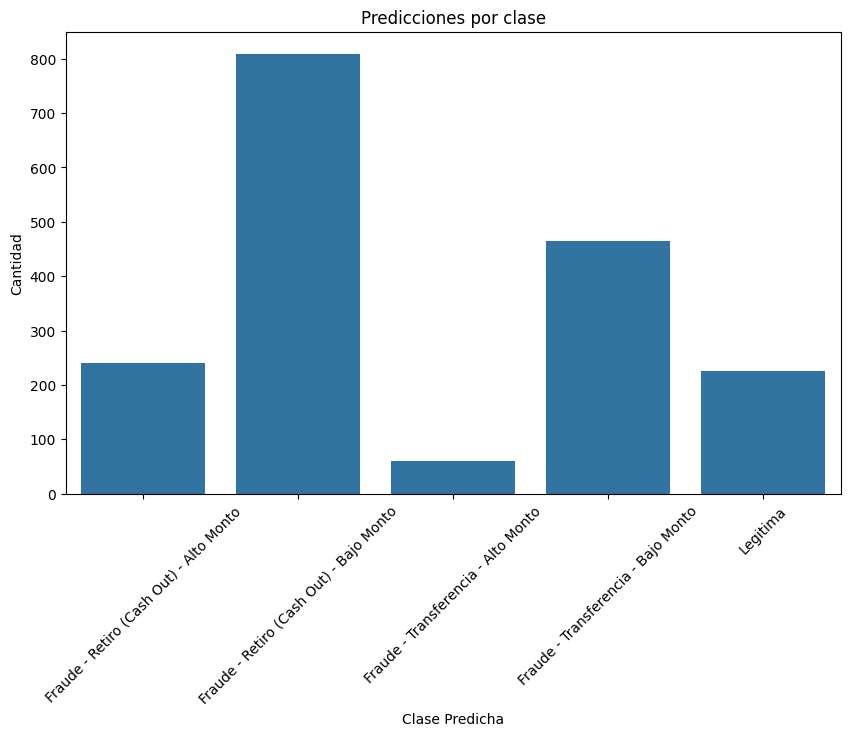

In [110]:
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.countplot(x=le.inverse_transform(y_pred_classes), order=le.classes_)
plt.title('Predicciones por clase')
plt.xticks(rotation=45)
plt.ylabel('Cantidad')
plt.xlabel('Clase Predicha')
plt.show()


📌 Celda: Visualización con PCA en 2D

Esta celda aplica Análisis de Componentes Principales (PCA) para reducir las dimensiones de los datos escalados a 2 componentes principales. Luego, grafica los puntos del conjunto de prueba en este espacio 2D de PCA, coloreando cada punto según la clase predicha por el modelo. Se crea una leyenda manual para asociar los colores con los nombres de las clases decodificadas, permitiendo visualizar cómo el modelo separa las diferentes clases en el espacio reducido de características.

57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


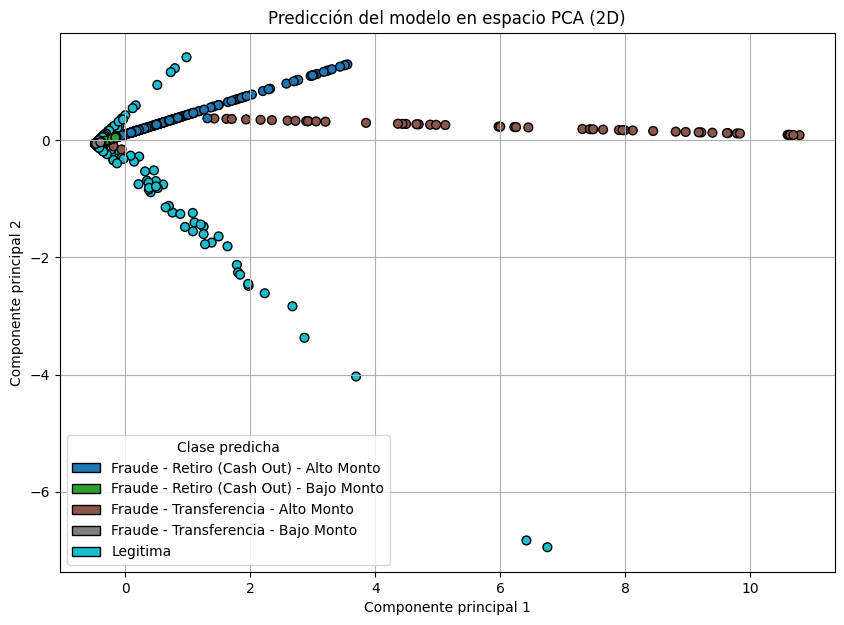

In [111]:
from sklearn.decomposition import PCA
from matplotlib.patches import Patch

# Reducimos a 2 dimensiones para visualización
pca = PCA(n_components=2)
X_test_pca = pca.fit_transform(X_test_scaled)

# Predicciones del modelo en el conjunto de prueba
y_pred = model.predict(X_test_scaled)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Visualización: puntos predichos por clase en el espacio PCA
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1],
                      c=y_pred_classes, cmap='tab10', edgecolor='k', s=40)

# Etiquetas de clase (decodificadas)
unique_classes = np.unique(y_pred_classes)
legend_labels = le.inverse_transform(unique_classes)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_classes)))

# Crear leyenda manual
legend_elements = [Patch(facecolor=colors[i], edgecolor='k', label=legend_labels[i]) for i in range(len(legend_labels))]

plt.legend(handles=legend_elements, title="Clase predicha")
plt.title('Predicción del modelo en espacio PCA (2D)')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.grid(True)
plt.show()


Similar a la celda anterior, esta celda también utiliza PCA para la visualización en 2D. Sin embargo, en lugar de mostrar las predicciones, grafica los puntos del conjunto de prueba coloreados según sus clases reales (`y_true_int`). Además, calcula y grafica la frontera de decisión del modelo en este espacio 2D de PCA. Para hacer esto, crea una grilla de puntos en el espacio PCA, los transforma de vuelta al espacio original utilizando la inversa de PCA, predice las clases para estos puntos transformados con el modelo, y luego grafica estas predicciones como un contorno en el espacio PCA. Esto proporciona una visualización de cómo el modelo divide el espacio de características para clasificar los datos.

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


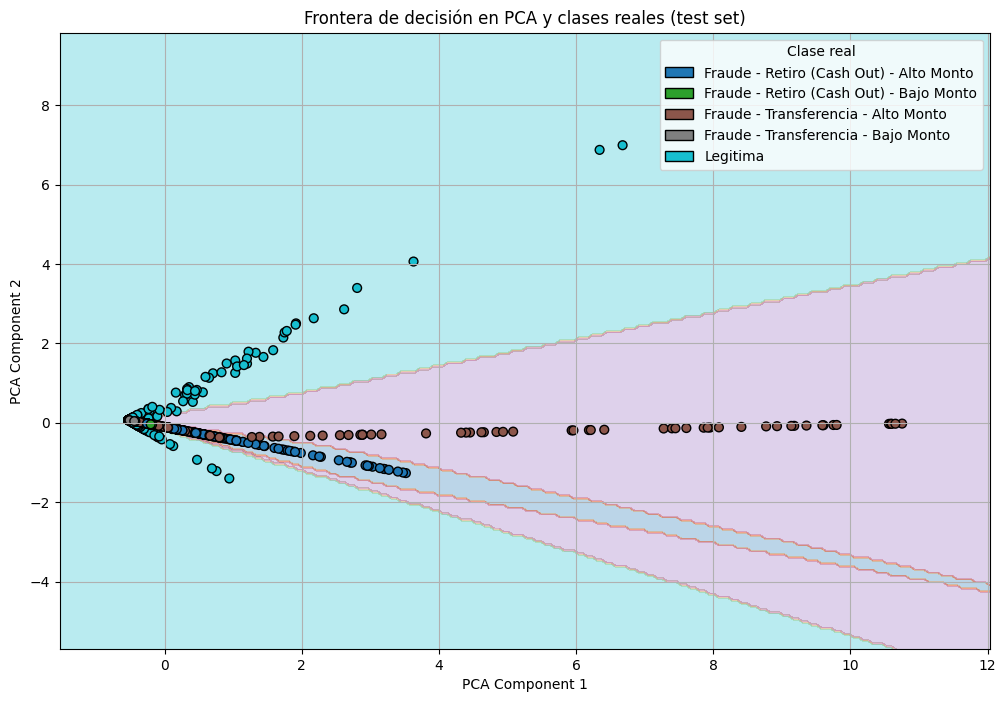

In [112]:
from sklearn.decomposition import PCA
from matplotlib.patches import Patch

# 1. Aplicar PCA a los datos escalados
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# 2. Crear grilla en el espacio PCA
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

grid_pca = np.c_[xx.ravel(), yy.ravel()]
grid_original = pca.inverse_transform(grid_pca)

# 3. Predecir con el modelo en el espacio original
Z = model.predict(grid_original)
Z = np.argmax(Z, axis=1)
Z = Z.reshape(xx.shape)

# 4. Obtener clases reales como enteros
y_true_int = np.argmax(y_test, axis=1)

# 5. Graficar
plt.figure(figsize=(12, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='tab10')  # Fronteras
scatter = plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1],
                      c=y_true_int, cmap='tab10', edgecolor='k', s=40)

# 6. Leyenda arreglada
labels = le.inverse_transform(np.unique(y_true_int))
colors = plt.cm.tab10(np.linspace(0, 1, len(labels)))
legend_elements = [Patch(facecolor=colors[i], edgecolor='k', label=labels[i]) for i in range(len(labels))]
plt.legend(handles=legend_elements, title="Clase real", loc="upper right")

plt.title('Frontera de decisión en PCA y clases reales (test set)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.grid(True)
plt.show()


57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


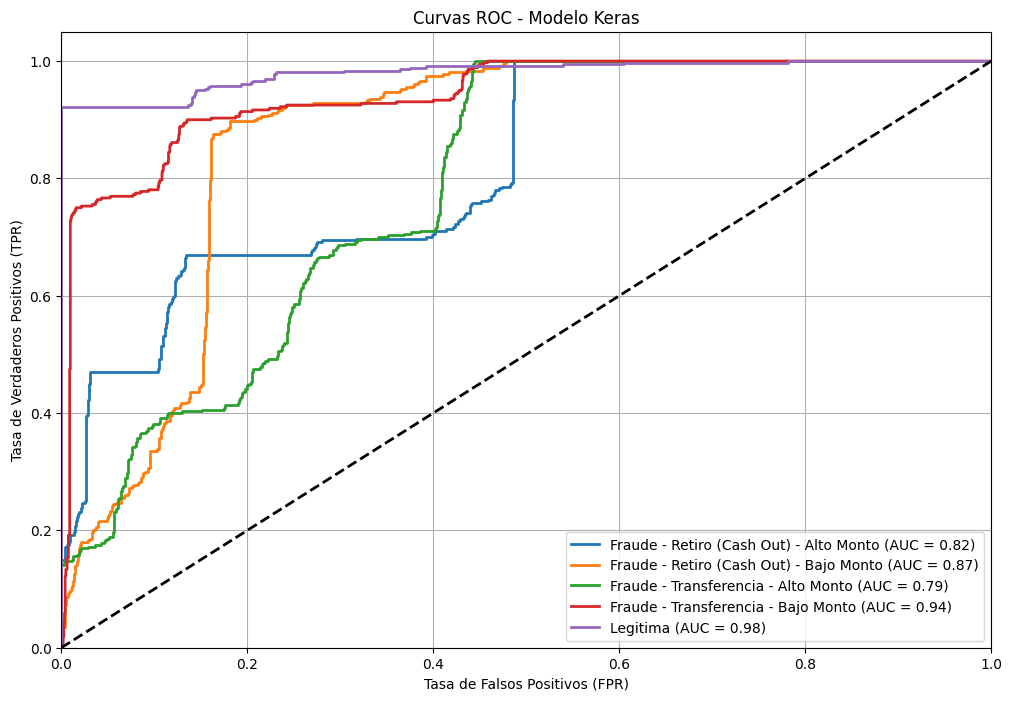

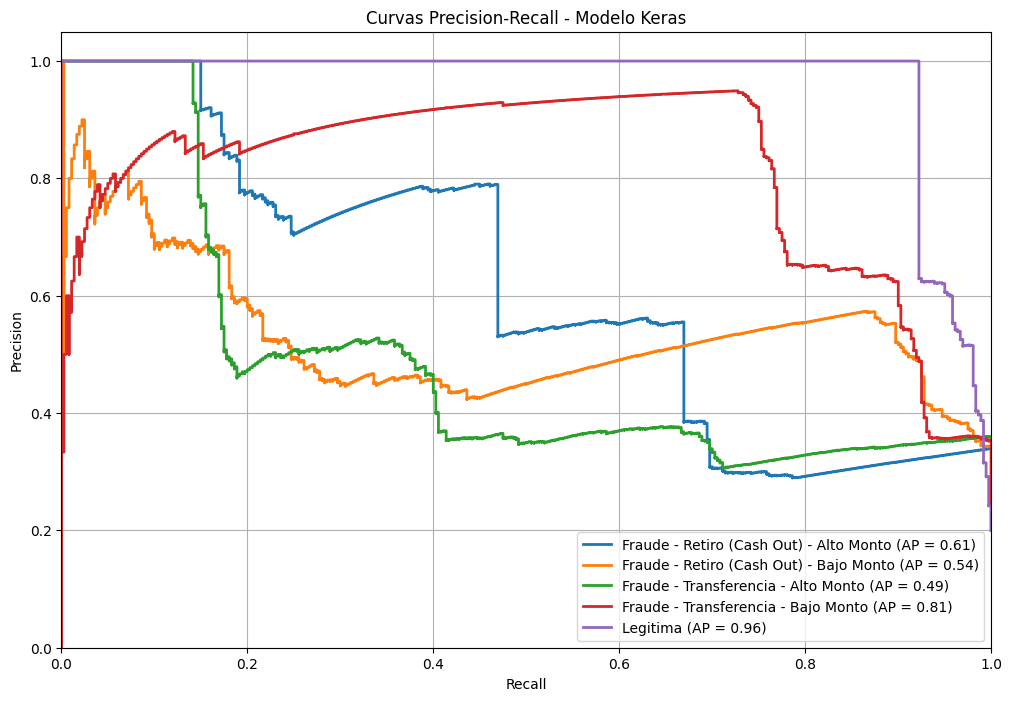

In [113]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# Calculate the probability scores for the Keras model
y_score_keras = model.predict(X_test_scaled)

# Binarizar las etiquetas verdaderas para el cálculo por clase
# Use le.classes_ to get the class names in the correct order
classes = le.classes_
y_test_binarized = label_binarize(np.argmax(y_test, axis=1), classes=np.arange(len(classes)))


# --- Curvas ROC ---
plt.figure(figsize=(12, 8))

# Curvas ROC para el modelo Keras
fpr_keras = dict()
tpr_keras = dict()
roc_auc_keras = dict()
for i in range(len(classes)):
    fpr_keras[i], tpr_keras[i], _ = roc_curve(y_test_binarized[:, i], y_score_keras[:, i])
    roc_auc_keras[i] = auc(fpr_keras[i], tpr_keras[i])
    plt.plot(fpr_keras[i], tpr_keras[i], lw=2, label=f'{classes[i]} (AUC = {roc_auc_keras[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2) # Curva de referencia aleatoria
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curvas ROC - Modelo Keras')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# --- Curvas Precision-Recall ---
plt.figure(figsize=(12, 8))

# Curvas Precision-Recall para el modelo Keras
precision_keras = dict()
recall_keras = dict()
average_precision_keras = dict()
for i in range(len(classes)):
    precision_keras[i], recall_keras[i], _ = precision_recall_curve(y_test_binarized[:, i], y_score_keras[:, i])
    average_precision_keras[i] = average_precision_score(y_test_binarized[:, i], y_score_keras[:, i])
    plt.step(recall_keras[i], precision_keras[i], where='post', lw=2, label=f'{classes[i]} (AP = {average_precision_keras[i]:.2f})')


plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curvas Precision-Recall - Modelo Keras')
plt.legend(loc="lower right")
plt.ylim([0.0, 1.05])
plt.xlim([0.0, 1.0])
plt.grid(True)
plt.show()

In [114]:
# Seleccionar 3 índices aleatorios del conjunto de prueba
np.random.seed(42) # for reproducibility
sample_indices = np.random.choice(len(X_test_scaled), 3, replace=False)

# Obtener los datos de prueba escalados y las etiquetas reales para estos índices
X_sample = X_test_scaled[sample_indices]
y_sample_real_encoded = np.argmax(y_test[sample_indices], axis=1) # Get the integer encoded real class

# Realizar predicciones con el modelo Keras
y_sample_pred_scores = model.predict(X_sample)
y_sample_pred_encoded = np.argmax(y_sample_pred_scores, axis=1) # Get the integer encoded predicted class

# Decodificar las etiquetas para mostrar los nombres de las clases
y_sample_real_labels = le.inverse_transform(y_sample_real_encoded)
y_sample_pred_labels = le.inverse_transform(y_sample_pred_encoded)

# Mostrar los resultados
print("Resultados para 3 casos de prueba:")
for i in range(len(sample_indices)):
    print(f"\nCaso de Prueba {i+1}:")
    print(f"  Predicción del modelo: {y_sample_pred_labels[i]}")
    print(f"  Resultado Real: {y_sample_real_labels[i]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Resultados para 3 casos de prueba:

Caso de Prueba 1:
  Predicción del modelo: Fraude - Retiro (Cash Out) - Bajo Monto
  Resultado Real: Fraude - Retiro (Cash Out) - Alto Monto

Caso de Prueba 2:
  Predicción del modelo: Fraude - Retiro (Cash Out) - Bajo Monto
  Resultado Real: Fraude - Retiro (Cash Out) - Alto Monto

Caso de Prueba 3:
  Predicción del modelo: Fraude - Retiro (Cash Out) - Bajo Monto
  Resultado Real: Fraude - Retiro (Cash Out) - Bajo Monto
